In [2]:
import nltk

# ============================================================
# 1. PREPARAR NLTK
# ============================================================
# Descargar las stopwords de NLTK, que son palabras comunes que se suelen ignorar en el análisis de texto.
nltk.download("stopwords", quiet=True)

# ============================================================
# 2. CREAR NUESTRO CORPUS
# ============================================================
texto = """
the cat sleeps on the sofa
the dog sleeps on the sofa
the cat plays in the garden
the dog plays in the garden
artificial intelligence helps students
artificial intelligence helps teachers
artificial intelligence changes technology
"""

# Separar las palabras
tokens = texto.lower().split()
print("TOKENS:")
print(tokens)

# Convertir el corpus a un objeto NLTK Text
corpus = nltk.Text(tokens)

# ============================================================
# 3. CONCORDANCIA
# ============================================================
print("CONCORDANCIA:")
corpus.concordance("cat", lines=3)

# Contar ocurrencias
print("Frecuencia de cat:", corpus.count("cat"))

# ============================================================
# 4. PALABRAS CON CONTEXTOS SIMILARES
# ============================================================
print("\nPALABRAS SIMILARES:")
corpus.similar("cat")

# ============================================================
# 5. CONTEXTOS COMUNES
# ============================================================
print("\nCONTEXTOS COMUNES:")
corpus.common_contexts(["cat", "dog"])

# ============================================================
# 6. COLOCACIONES
# ============================================================
print("\nCOLOCACIONES:")
corpus.collocations(num=5)

TOKENS:
['the', 'cat', 'sleeps', 'on', 'the', 'sofa', 'the', 'dog', 'sleeps', 'on', 'the', 'sofa', 'the', 'cat', 'plays', 'in', 'the', 'garden', 'the', 'dog', 'plays', 'in', 'the', 'garden', 'artificial', 'intelligence', 'helps', 'students', 'artificial', 'intelligence', 'helps', 'teachers', 'artificial', 'intelligence', 'changes', 'technology']
CONCORDANCIA:
Displaying 2 of 2 matches:
                                  the cat sleeps on the sofa the dog sleeps on 
e sofa the dog sleeps on the sofa the cat plays in the garden the dog plays in 
Frecuencia de cat: 2

PALABRAS SIMILARES:
dog

CONTEXTOS COMUNES:
the_sleeps the_plays

COLOCACIONES:
artificial intelligence; intelligence helps


# Frecuencias

Frecuencia original:
[('la', 32), (',', 31), ('.', 28), ('y', 23), ('de', 22), ('los', 22)]

Frecuencia filtrada:
[('macondo', 7), ('familia', 6), ('buendía', 6), ('pueblo', 5), ('soledad', 4), ('historia', 4), ('tiempo', 4), ('habitantes', 4), ('años', 3), ('vida', 3)]

Frecuencia absoluta de 'familia': 6
Frecuencia relativa de 'familia': 0.022900763358778626
Total de palabras: 262
Palabras diferentes: 199

Frecuencia de bigramas:
[(('familia', 'buendía'), 3), (('josé', 'arcadio'), 2), (('arcadio', 'buendía'), 2), (('cien', 'años'), 1), (('años', 'soledad'), 1)]

Frecuencia de collocations:
josé arcadio; familia buendía; arcadio buendía
None


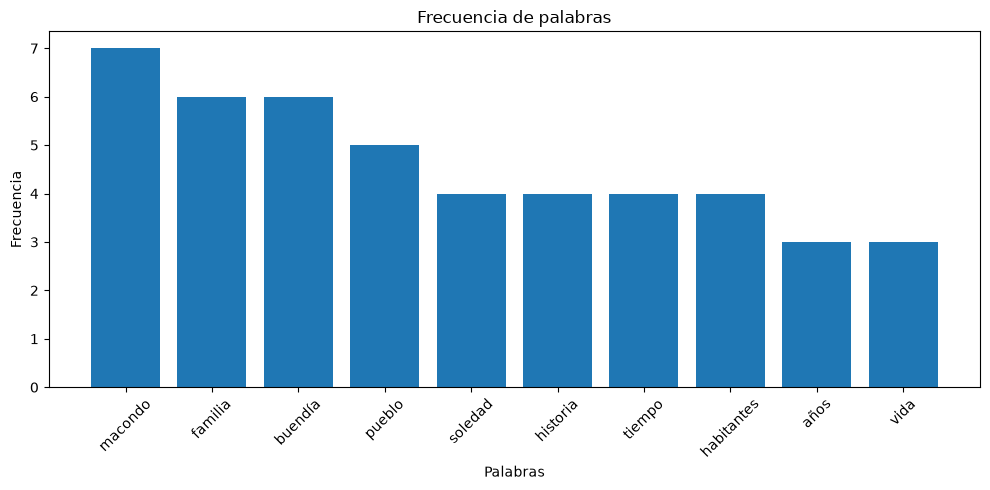

In [15]:
import nltk
import string
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
from pathlib import Path
from os import path

# ============================================================
# 1. DESCARGAR STOPWORDS
# ============================================================
nltk.download("stopwords", quiet=True)

# ============================================================
# 2. CREAR CORPUS FROM FILE
# ============================================================
text_path = path.join("data", "cien_anos_de_soledad_resumen.txt")
texto = Path(text_path).read_text(
    encoding="utf-8"
)

# Tokenizar y normalizar a minúsculas
tokens = nltk.wordpunct_tokenize(texto.lower())

# ============================================================
# 3. FRECUENCIA SIN FILTRAR
# ============================================================
fd_original = nltk.FreqDist(tokens)

print("Frecuencia original:")
print(fd_original.most_common(6))

# ============================================================
# 4. ELIMINAR PUNTUACIÓN
# ============================================================
punctuation = set(string.punctuation)

tokens_limpios = [
    word for word in tokens
    if word not in punctuation and word.isalpha()
]

# ============================================================
# 5. ELIMINAR STOPWORDS EN ESPAÑOL
# ============================================================
sw_es = set(stopwords.words("spanish"))

tokens_filtrados = [
    word for word in tokens_limpios
    if word not in sw_es
]

# ============================================================
# 6. FRECUENCIA FINAL
# ============================================================
fd = nltk.FreqDist(tokens_filtrados)

print("\nFrecuencia filtrada:")
print(fd.most_common(10))

print("\nFrecuencia absoluta de 'familia':", fd["familia"])
print("Frecuencia relativa de 'familia':", fd.freq("familia"))
print("Total de palabras:", fd.N())
print("Palabras diferentes:", fd.B())

# ============================================================
# 7. COLLOCATIONS VS BIAGRAMS
# ============================================================
biaggramas = list(nltk.bigrams(tokens_filtrados))
fd_biagramas = nltk.FreqDist(biaggramas)
print("\nFrecuencia de bigramas:")
print(fd_biagramas.most_common(5))

print("\nFrecuencia de collocations:")
corpus = nltk.Text(tokens_filtrados)
print(corpus.collocations(num=5))

# ============================================================
# 8. GRAFICAR FRECUENCIAS
# ============================================================
fig, axes = plt.subplots(figsize=(10, 5))
palabras, frecuencias = zip(*fd.most_common(10))

axes.bar(palabras, frecuencias)
axes.set_ylim(bottom=0)
axes.set_title("Frecuencia de palabras")
axes.set_xlabel("Palabras")
axes.set_ylabel("Frecuencia")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Sinonimos y antonimos

In [16]:
import nltk
from nltk.corpus import wordnet

# ============================================================
# 1. DESCARGAR WORDNET
# ============================================================
nltk.download("wordnet", quiet=True)

# ============================================================
# 2. BUSCAR SIGNIFICADOS DE UNA PALABRA
# ============================================================
word = "happy"

synsets = wordnet.synsets(word, pos=wordnet.ADJ)

print("Número de significados:", len(synsets))

for syn in synsets:
    print("\nSynset:", syn.name())
    print("Definición:", syn.definition())
    print("Ejemplos:", syn.examples())

# ============================================================
# 3. OBTENER SINÓNIMOS Y ANTÓNIMOS
# ============================================================
synonyms = set()
antonyms = set()

for syn in synsets:
    for lemma in syn.lemmas():

        # Obtener sinónimos
        synonyms.add(lemma.name())

        # Obtener antónimos
        for antonym in lemma.antonyms():
            antonyms.add(antonym.name())

# Eliminar la palabra original de los sinónimos
synonyms.discard(word)

print("\nSinónimos:", sorted(synonyms))
print("Antónimos:", sorted(antonyms))

Número de significados: 4

Synset: happy.a.01
Definición: enjoying or showing or marked by joy or pleasure
Ejemplos: ['a happy smile', 'spent many happy days on the beach', 'a happy marriage']

Synset: felicitous.s.01
Definición: marked by good fortune
Ejemplos: ['a felicitous life', 'a happy outcome']

Synset: glad.s.01
Definición: eagerly disposed to act or to be of service
Ejemplos: ['glad to help']

Synset: happy.s.03
Definición: well expressed and to the point
Ejemplos: ['a happy turn of phrase', 'a few well-chosen words']

Sinónimos: ['felicitous', 'glad', 'well-chosen']
Antónimos: ['unhappy']


# Stemming y lematización

In [22]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer

# ============================================================
# 1. DESCARGAR LOS DATOS NECESARIOS
# ============================================================
nltk.download("wordnet", quiet=True)

# ============================================================
# 2. INICIALIZAR HERRAMIENTAS
# ============================================================
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# ============================================================
# 3. DEFINIR PALABRAS Y SU CATEGORÍA GRAMATICAL
# ============================================================
words = [
    ("studies", "n"),    # Sustantivo
    ("running", "v"),    # Verbo
    ("cats", "n"),       # Sustantivo
    ("mice", "n"),       # Sustantivo
    ("better", "a"),     # Adjetivo
    ("deceases", "v"),    # Verbo
    ("worse", "a"),        # Adjetivo
    ("lovers", "n")       # Sustantivo
]

# ============================================================
# 4. COMPARAR STEMMING Y LEMATIZACIÓN
# ============================================================
for word, pos in words:
    stem = stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    print(f"{word:12} | Stem: {stem:10} | Lemma: {lemma}")

studies      | Stem: studi      | Lemma: study
running      | Stem: run        | Lemma: run
cats         | Stem: cat        | Lemma: cat
mice         | Stem: mice       | Lemma: mouse
better       | Stem: better     | Lemma: good
deceases     | Stem: deceas     | Lemma: decease
worse        | Stem: wors       | Lemma: bad
lovers       | Stem: lover      | Lemma: lover


# Web Scrapping y Crawling

HTML original:
<!DOCTYPE html><html lang="es" dir="ltr" prefix="content: http://purl.org/rss/1.0/modules/content/ dc: http://purl.org/dc/terms/ foaf: http://xmlns.com/foaf/0.1/ og: http://ogp.me/ns# rdfs: http://www

Texto extraído:
Nuestra Universidad Online | VIU España Pasar al contenido principal Buscar Nuestra institución Grados Área de conocimiento Grados en Artes y Humanidades Grado en Traducción e Interpretación Grado en Lengua y Literatura Españolas Grado en Musicología Grado en Historia Grado en Humanidades Grados en 

Primeras palabras:
['universidad', 'online', 'viu', 'españa', 'pasar', 'contenido', 'principal', 'buscar', 'institución', 'grados', 'área', 'conocimiento', 'grados', 'artes', 'humanidades', 'grado', 'traducción', 'interpretación', 'grado', 'lengua']

Palabras más frecuentes:
[('máster', 237), ('universitario', 190), ('grado', 87), ('educación', 63), ('formación', 62), ('gestión', 44), ('profesorado', 29), ('u', 28), ('islas', 28), ('comunicación', 26)]


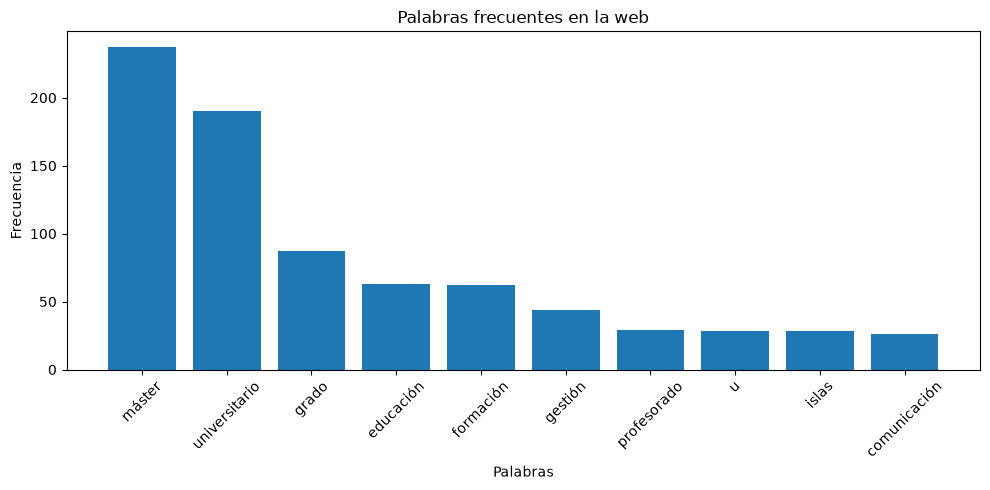

In [24]:
import nltk
from urllib import request
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

# ============================================================
# 1. DESCARGAR RECURSOS NLTK
# ============================================================
nltk.download("stopwords", quiet=True)

# ============================================================
# 2. DESCARGAR HTML DE LA PÁGINA WEB
# ============================================================
url = "https://www.universidadviu.com/es/quienes-somos"

req = request.Request(
    url,
    headers={"User-Agent": "Python-NLTK-Study/1.0"}
)

with request.urlopen(req, timeout=15) as response:
    encoding = response.headers.get_content_charset() or "utf-8"
    html = response.read().decode(encoding, errors="replace")

print("HTML original:")
print(html[:200])

# ============================================================
# 3. EXTRAER TEXTO CON BEAUTIFULSOUP
# ============================================================
soup = BeautifulSoup(html, "html.parser")

# Eliminar elementos no relevantes
for tag in soup(["script", "style", "nav", "footer"]):
    tag.decompose()

# Extraer el contenido textual
texto = soup.get_text(separator=" ", strip=True)

print("\nTexto extraído:")
print(texto[:300])

# ============================================================
# 4. TOKENIZAR CON NLTK
# ============================================================
tokens = nltk.wordpunct_tokenize(texto.lower())

# ============================================================
# 5. ELIMINAR PUNTUACIÓN Y STOPWORDS
# ============================================================
sw_es = set(nltk.corpus.stopwords.words("spanish"))

tokens_filtrados = [
    word for word in tokens
    if word.isalpha() and word not in sw_es
]

# ============================================================
# 6. CREAR CORPUS NLTK
# ============================================================
corpus = nltk.Text(tokens_filtrados)

print("\nPrimeras palabras:")
print(corpus[:20])

# ============================================================
# 7. ANALIZAR FRECUENCIAS
# ============================================================
fd = nltk.FreqDist(corpus)

print("\nPalabras más frecuentes:")
print(fd.most_common(10))

# ============================================================
# 8. GRAFICAR RESULTADOS
# ============================================================
palabras, frecuencias = zip(*fd.most_common(10))

fig, axes = plt.subplots(figsize=(10, 5))
axes.bar(palabras, frecuencias)
axes.set_title("Palabras frecuentes en la web")
axes.set_xlabel("Palabras")
axes.set_ylabel("Frecuencia")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()